## LLM의 문장 생성과 Transformer


### 대규모 언어 모델이란 무엇인가

대규모 언어 모델(LLM, Large Language Model)은 많은 파라미터와 방대한 텍스트를 사용해 언어 패턴을 학습한 모델이다. 문맥에 어울리는 텍스트를 생성하며, 글을 요약하거나 질문에 답하는 데 활용된다.

모델은 텍스트를 토큰(token)이라는 작은 단위로 처리한다.

GPT와 같은 생성형 언어 모델은 원문의 앞선 토큰을 입력으로, 실제 다음 토큰을 정답으로 삼아 사전학습한다. 예를 들어 문장을 `하늘 / 이 / 맑 / 다`로 나누었다면, 입력이 `하늘 / 이 / 맑`일 때 다음 토큰의 정답은 `다`이다. 생성할 때는 앞선 문맥으로 다음 토큰을 예측하며 텍스트를 이어 간다.


### 토큰과 임베딩

토큰은 한 글자나 단어의 일부 또는 단어 하나에 해당할 수 있다. 토크나이저(tokenizer)는 텍스트를 토큰으로 나누고, 정해진 어휘 목록을 조회해 각 토큰을 고유한 정수 ID에 매핑한다.

모델은 토큰 ID에 대응하는 벡터인 토큰 임베딩(token embedding)을 가져온다. 이 벡터의 값은 모델이 학습하면서 조정된다.



### Transformer의 역할

다음 토큰을 예측하려면 입력에 어떤 토큰이 있는지와 토큰들이 어떤 관계를 이루는지를 함께 반영해야 한다. Transformer는 토큰 사이의 관계를 이용해 각 토큰을 나타내는 벡터를 갱신하는 신경망 구조로, 언어 모델은 이를 사용해 앞선 문맥을 다음 토큰의 예측에 반영한다.

문맥 표현은 주변 토큰과의 관계를 반영한 벡터다. 예를 들어 “대출 상담을 위해 찾은 은행”과 “가을에 주운 은행”에서 ‘은행’은 앞선 표현들과 결합한 의미가 다르다. Transformer는 이런 문맥의 차이를 토큰의 벡터에 반영한다.

블록은 여러 계산 층을 하나로 묶은 단위이며, Transformer는 이런 블록을 여러 개 쌓은 구조다.

LLM은 언어를 예측하는 모델을, Transformer는 그 모델을 구성하는 신경망 구조를, Attention은 구조 안에서 정보를 모으는 계산을 가리킨다.

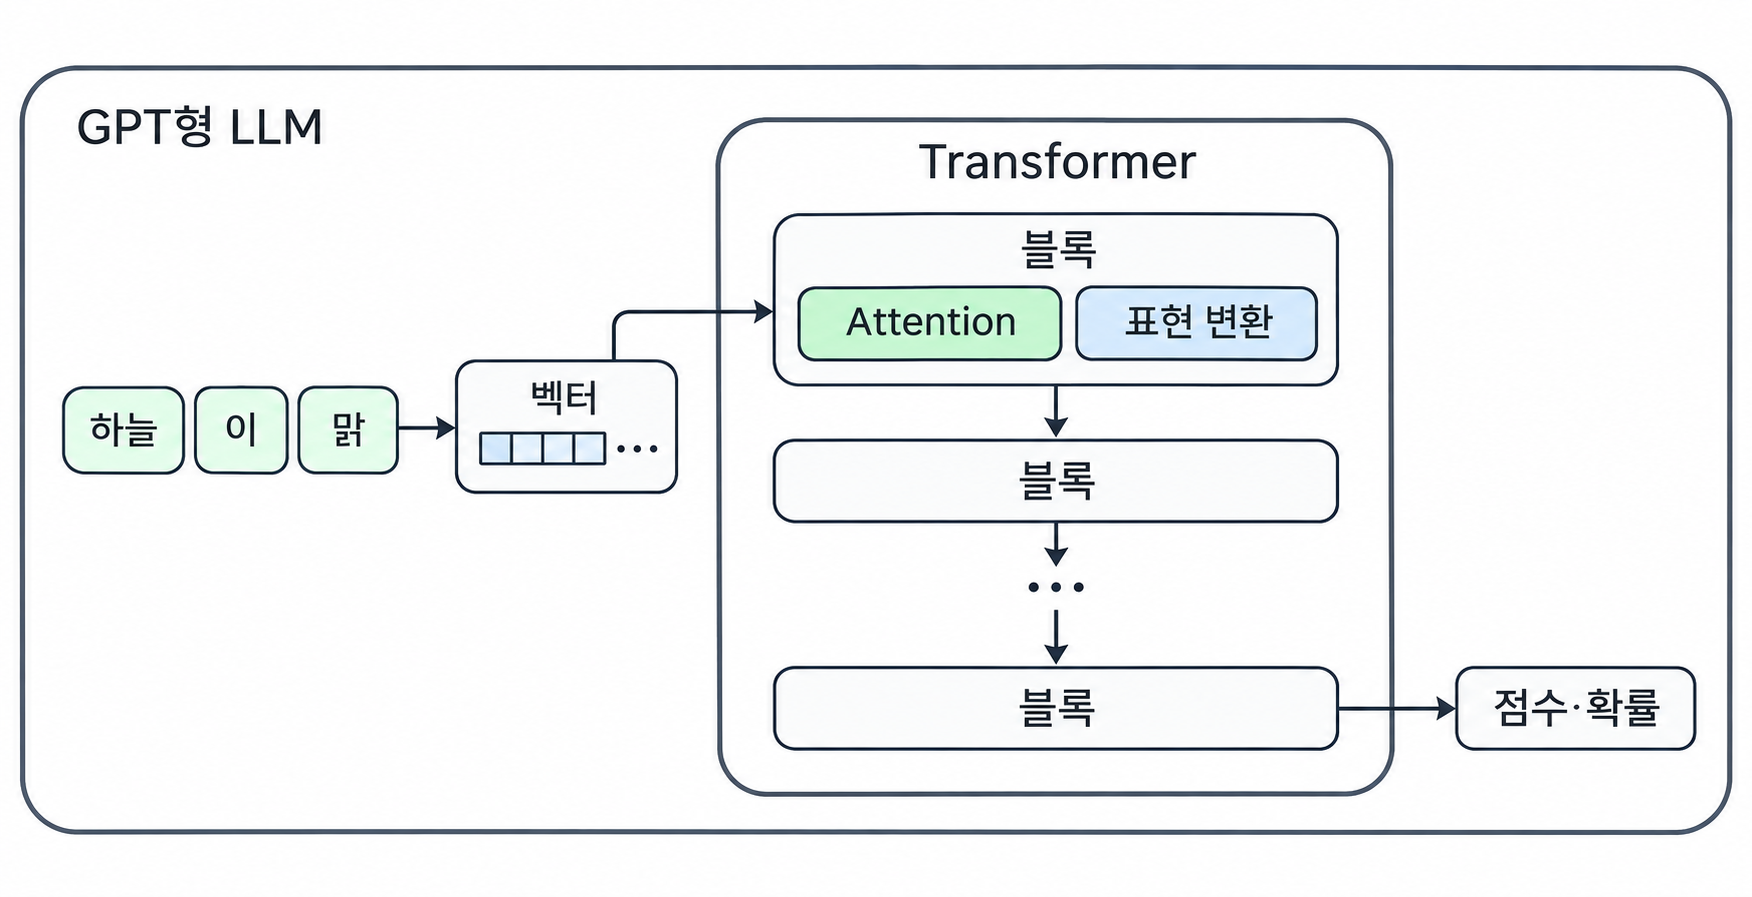


## Attention

### Attention의 원리

토큰과 위치 정보를 반영한 벡터는 Attention의 입력이 된다. Attention은 각 위치에서 참고할 토큰의 비중을 정하고, 그 비중으로 정보를 모아 현재 위치의 표현을 갱신하는 계산이다. 정보를 모으는 위치와 참고할 위치가 같은 입력 토큰열 안에 있으면 자기 어텐션(self-attention)이라고 한다.

모델은 각 토큰의 표현에 서로 다른 학습 가능한 선형 변환을 적용해 Query·Key·Value라는 세 벡터를 만든다.

| 벡터 | 역할 | 계산에서의 쓰임 |
| --- | --- | --- |
| Query (Q) | 현재 위치가 정보를 찾는 기준 | 참고할 위치들의 Key와 비교해 관련성 점수를 구한다. |
| Key (K) | 참고할 위치의 정보를 비교하기 위한 표현 | Query와의 관련성 점수를 통해 해당 위치의 참고 비중을 정하는 데 쓰인다. |
| Value (V) | 참고할 위치에서 가져올 정보 | 계산된 참고 비중을 곱해 더하여 출력 벡터를 만든다. |

예를 들어 `하늘 / 이 / 맑`에서 `맑` 위치의 출력을 구하려면, `맑`의 Query를 세 토큰 각각의 Key와 비교해 관련성 점수를 구한다. 이 점수들을 합이 1인 양수 비중으로 바꾸는 함수가 Softmax이며, 점수가 높은 위치에 더 큰 참고 비중을 준다. Query와 Key가 입력에서 만들어지므로 참고 비중도 입력 문맥에 따라 달라진다.

각 토큰의 Value에 해당 비중을 곱해 더하면 문맥 정보를 모은 벡터인 `맑` 위치의 Attention 출력이 된다. 이처럼 비중을 곱해 더하는 계산을 가중합이라고 한다. 이 문맥 표현은 나머지 Transformer 계산과 출력층을 거쳐 `맑` 다음에 올 토큰을 예측하는 데 사용된다.

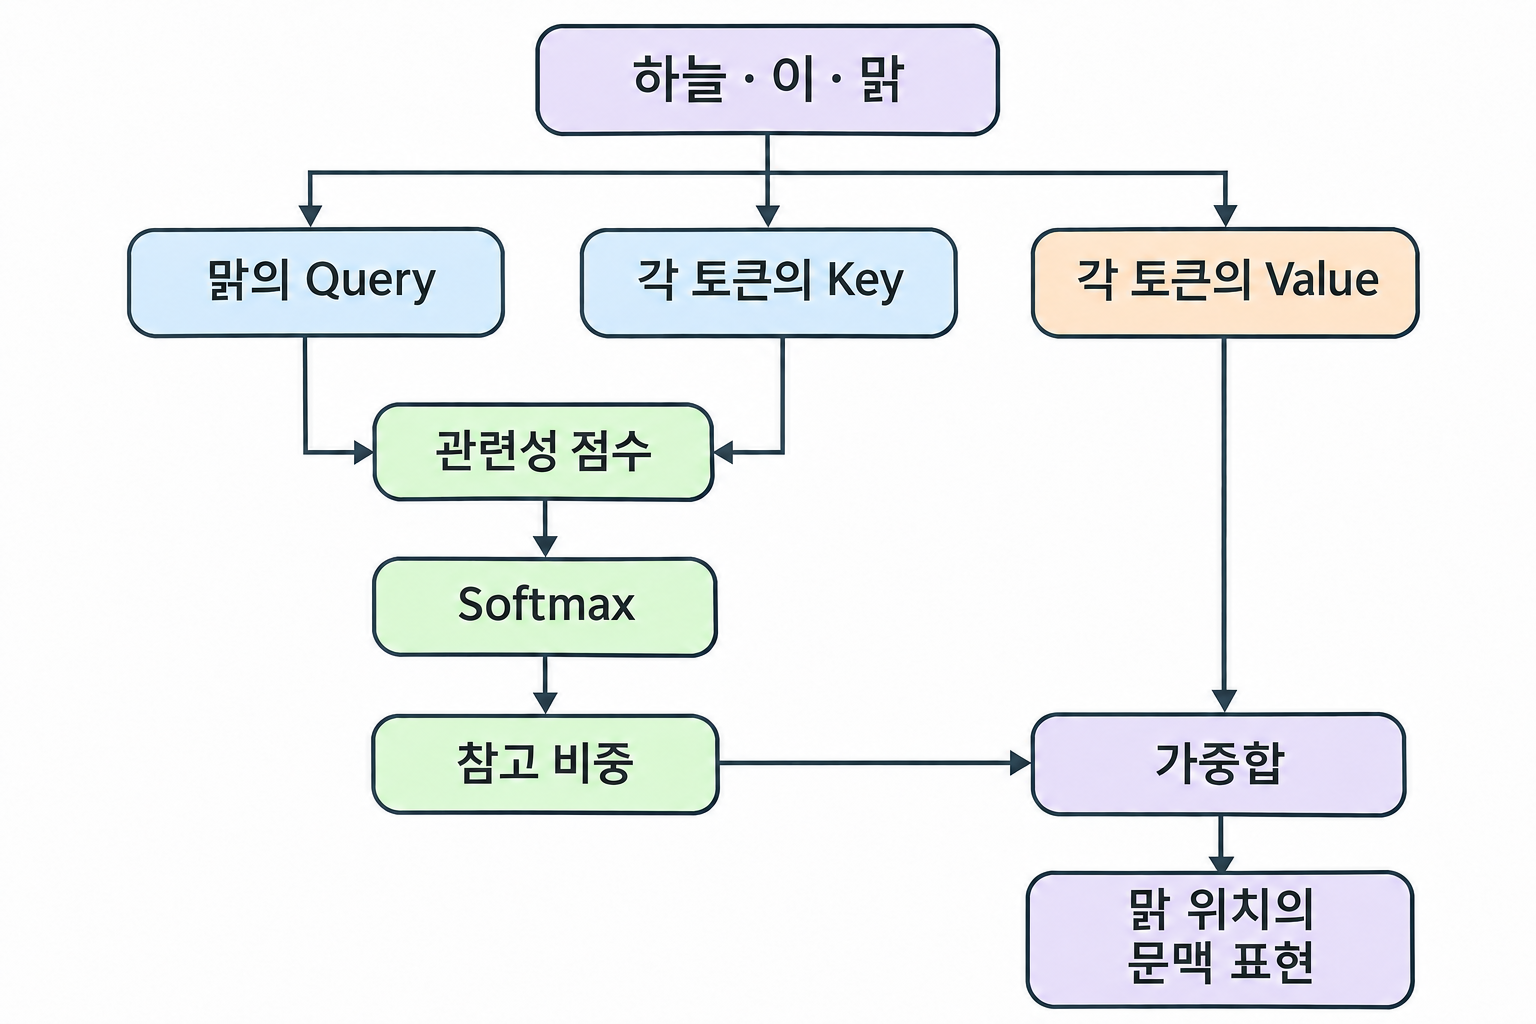


### Attention의 계산 과정

각 토큰의 Query·Key·Value를 행으로 쌓은 행렬을 각각 $Q$, $K$, $V$라고 하면, 관련성 비교부터 참고 비중 계산과 가중합까지를 하나의 수식으로 나타낼 수 있다.

$$
\operatorname{Attention}(Q,K,V)=\operatorname{softmax}\left(\frac{QK^\top}{\sqrt{d_k}}\right)V
$$

$QK^\top$은 위치 쌍마다 구한 관련성 점수이며, $K^\top$은 K의 행과 열을 바꾼 행렬이다. $d_k$는 Query와 Key 벡터를 이루는 숫자의 개수로, $\sqrt{d_k}$로 나누어 점수의 크기를 조절한다.

Softmax를 각 행에 적용하면 참고 비중이 되고, 여기에 $V$를 곱하면 각 위치의 Value를 그 비중으로 가중합한 Attention 출력이 된다.


### 멀티헤드 Attention

멀티헤드 Attention은 같은 입력을 서로 다른 가중치로 여러 번 Attention 계산한 뒤, 각 결과 벡터를 결합하는 연산이다.

각 Attention 계산을 담당하는 단위를 헤드(head)라고 한다. 모든 헤드에 같은 입력 벡터들이 전달되며, 각 헤드는 자신만의 학습 가능한 Q·K·V 변환 가중치로 Query·Key·Value를 만든다.

여러 헤드를 사용하면 같은 입력에 대해 서로 다른 참고 비중을 계산하고, 다양한 문맥 정보를 함께 활용할 수 있다. 헤드별 참고 패턴은 학습 데이터와 가중치에 따라 달라진다.

각 헤드의 출력은 토큰 위치별로 이어 붙인 뒤, 학습 가능한 선형층으로 조합해 최종 출력 벡터를 만든다.

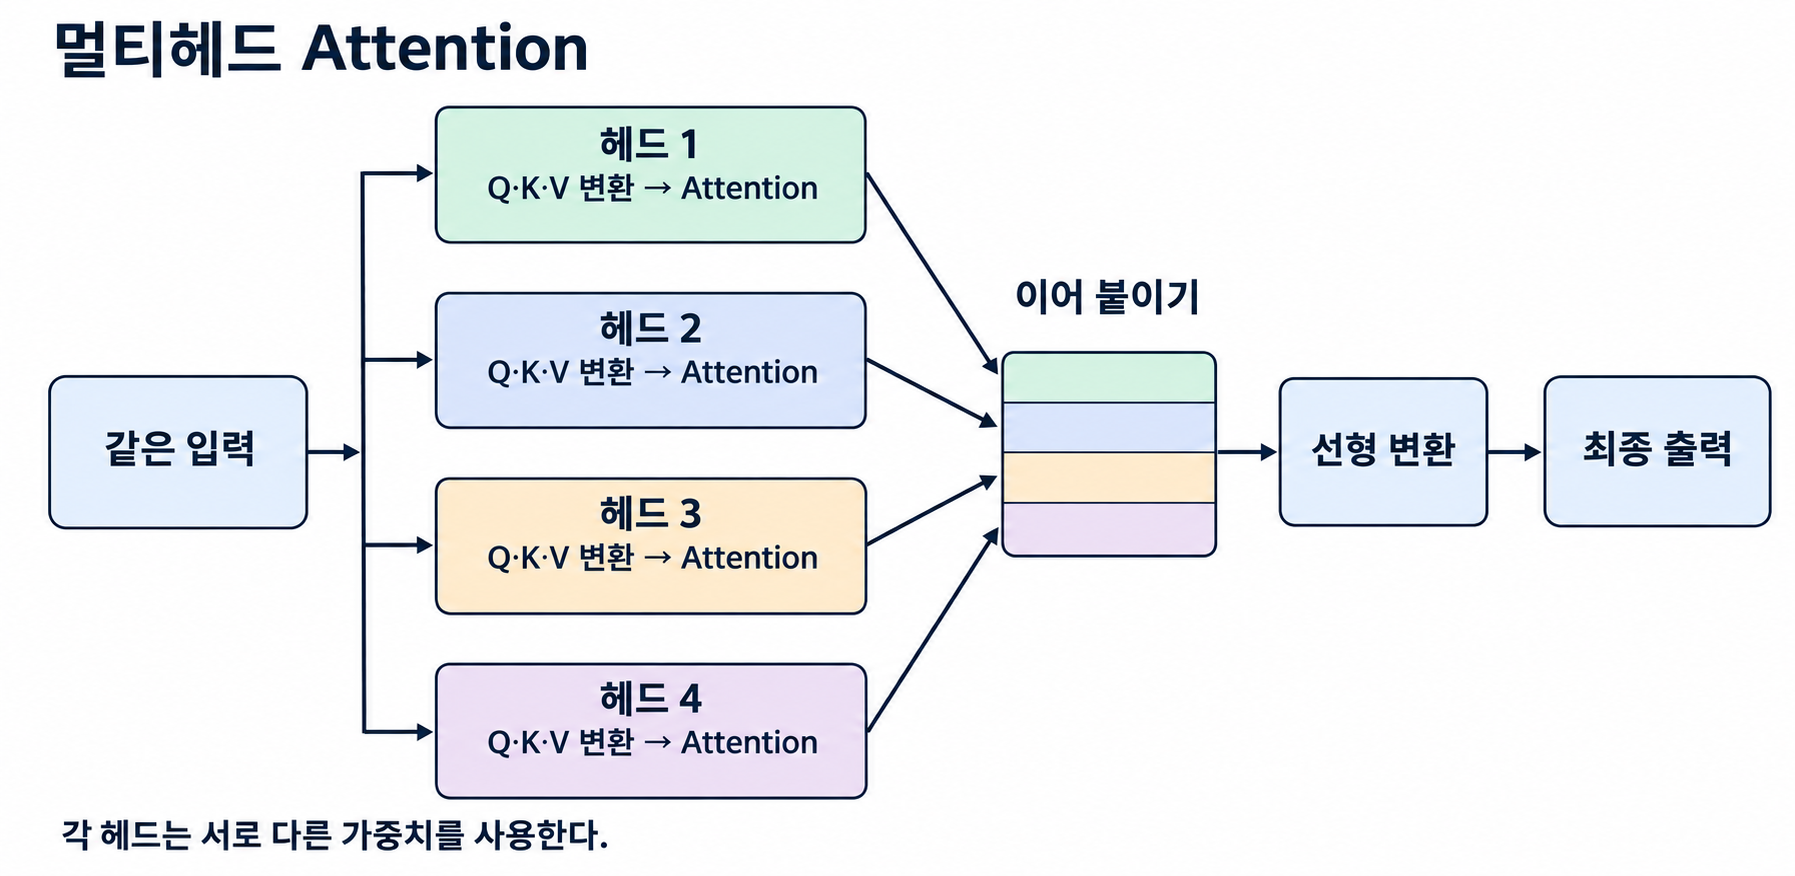


### 미래 위치를 가리는 Causal mask

다음 토큰을 예측하는 모델에서는 정보를 가져올 위치도 제한해야 한다. 학습할 때 입력이 `하늘 / 이 / 맑`이면 각 위치의 정답은 `이 / 맑 / 다`다. 이때 `하늘` 위치가 뒤의 `이`를 참고하면 예측해야 할 정답을 미리 읽게 된다. Causal mask는 각 위치가 자기 위치와 앞선 위치만 참고하도록 제한한다.

| 현재 위치 | 참고할 수 있는 입력 | 다음 토큰의 정답 |
| --- | --- | --- |
| 하늘 | 하늘 | 이 |
| 이 | 하늘 / 이 | 맑 |
| 맑 | 하늘 / 이 / 맑 | 다 |

미래 위치의 점수를 음의 무한대로 바꾸면 Softmax를 거친 뒤 그 위치의 비중은 0이 된다. 이렇게 각 위치가 참고할 범위를 제한하면서 여러 위치의 예측을 함께 계산한다.

그림은 임의의 관련성 점수에 causal mask와 Softmax를 적용해 계산한 예시다. 행은 정보를 모으는 위치, 열은 참고하는 위치이며, 색이 진할수록 참고 비중이 크다. 대각선 위의 비중은 0이고 각 행의 비중 합은 1이다.

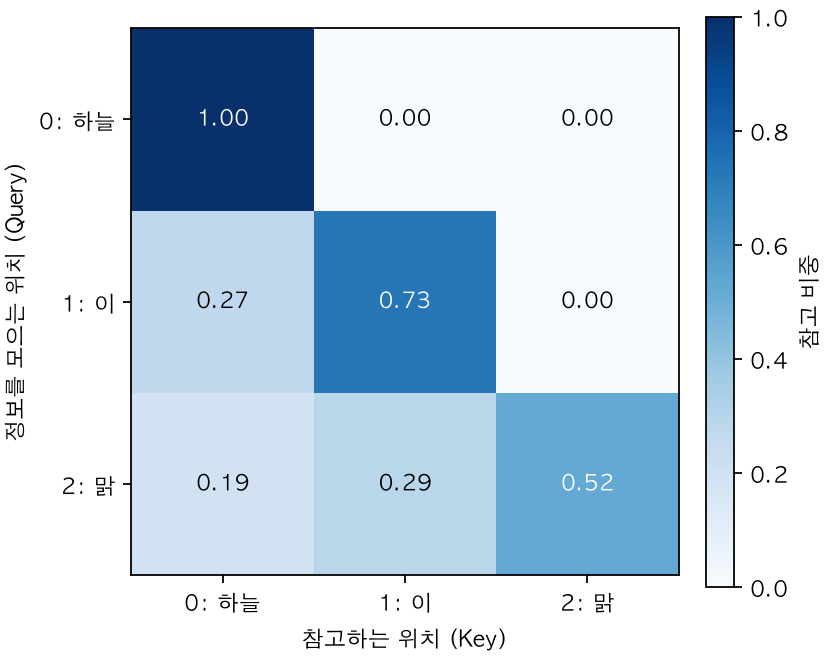

생성에서도 각 위치는 자기 위치와 앞선 위치만 참고하는 규칙을 따른다.


## Encoder와 Decoder

원래 Transformer는 Encoder와 Decoder를 함께 사용하는 구조로 제안되었다.

그림은 정규화를 먼저 적용하는 Encoder–Decoder 구조의 예다.

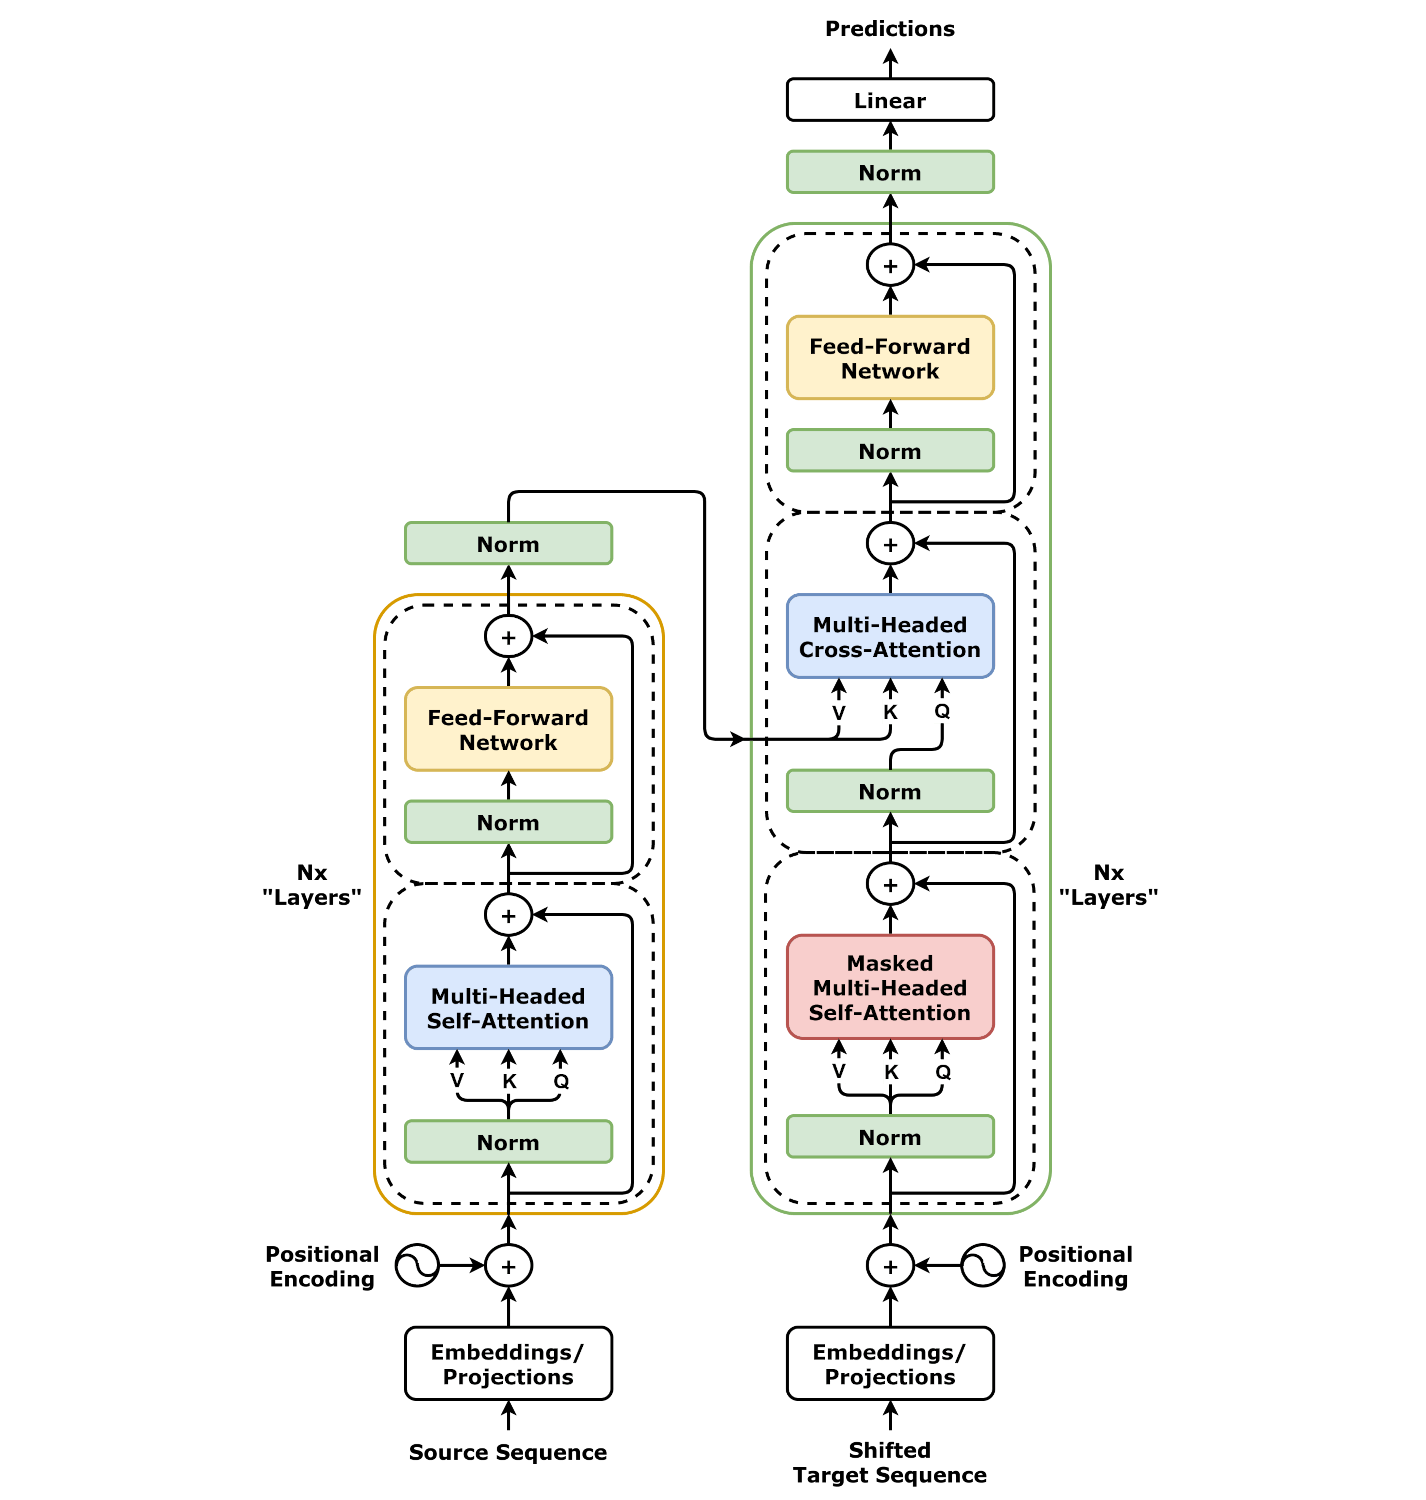

왼쪽은 Encoder, 오른쪽은 Decoder이며, 계산 흐름은 아래에서 위로 읽는다.

Encoder는 입력 토큰열 전체를 읽고 각 토큰을 문맥이 반영된 벡터로 바꾼다. Encoder의 Self-attention에서는 각 위치가 입력의 앞뒤 모든 위치를 참고할 수 있다. 이렇게 만든 토큰별 벡터가 Encoder의 출력이다.

Decoder는 생성 중인 출력 토큰열에 Causal self-attention을 적용해 각 위치가 자기 위치와 앞선 위치만 참고하도록 한다. 이어서 Cross-attention으로 Encoder의 출력 정보를 가져온다. Cross-attention에서는 Query를 Decoder의 표현에서 만들고, Key와 Value를 Encoder의 출력에서 만든다. 따라서 Decoder는 앞선 출력 문맥과 입력 토큰열의 정보를 함께 반영해 다음 토큰을 예측할 수 있다.

- `Shifted Target Sequence`: 학습 때 각 위치가 다음 토큰을 예측하도록, 정답 출력 토큰열을 한 토큰만큼 오른쪽으로 옮긴 Decoder 입력이다.
- `Projections`: 입력 벡터를 학습 가능한 선형 변환으로 바꾸는 것을 뜻한다.
- `N× Layers`: 테두리로 묶인 블록을 N개 쌓는다는 뜻이다.



## Transformer 블록

Transformer 블록은 Attention, 잔차 연결, 정규화, FFN으로 구성된다. 한 블록이 갱신한 토큰별 벡터는 다음 블록의 입력이 되며, 각 블록은 서로 다른 가중치를 학습한다.


### 잔차 연결

잔차 연결(residual connection)은 입력을 Attention이나 FFN의 계산 결과에 더하는 연결이다. 기존 표현에 새 정보를 더하고, 역전파 때 학습 신호가 앞쪽 층까지 전달되도록 도와 깊은 모델의 학습을 원활하게 한다. 그림에서 Attention이나 FFN 옆을 우회해 `+`로 들어가는 실선이 이 연결이다.

### LayerNorm

LayerNorm은 각 토큰 벡터의 평균과 분산을 이용해 값들의 크기를 조절하고, 학습 가능한 가중치와 편향으로 다시 조정한다. 이 과정은 여러 블록을 쌓은 모델의 학습을 안정적으로 돕는다. 블록 안에서 Attention이나 FFN과 함께 사용하며, 적용하는 순서는 모델 구조에 따라 달라진다.

### FFN

FFN(feed-forward network)은 각 토큰의 벡터에 독립적으로 적용하는 다층 퍼셉트론(MLP)이다. 일반적으로 선형층 → 비선형 활성화 함수 → 선형층으로 구성되며, 모든 토큰 위치에 같은 가중치를 사용한다.

Attention이 여러 토큰의 정보를 모으면, FFN은 그렇게 얻은 각 토큰의 벡터를 변환한다.



## 다음 토큰의 점수와 확률

### 문맥 표현을 다음 토큰의 점수로 바꾸기

텍스트를 생성하는 Transformer는 Decoder의 출력 벡터를 어휘별 점수로 바꾼다. 언어 모델 헤드(LM Head)는 이 벡터를 받아 어휘 목록의 토큰마다 점수를 하나씩 계산하는 마지막 출력층이며, 이 점수를 로짓(logit)이라고 한다.

```text
토큰 ID → 임베딩·위치 정보 → Decoder 블록 → LM Head → 어휘별 점수
```

Decoder가 처리하는 토큰열이 `하늘 / 이 / 맑`이면 각 위치에서 어휘 전체의 점수가 나온다. 학습에서는 세 위치의 예측을 각각 정답 `이 / 맑 / 다`와 비교한다. 생성에서는 마지막인 `맑` 위치의 점수로 다음 토큰 하나를 선택한다.


### 다음 토큰의 확률 분포

LM Head가 구한 로짓에 Softmax를 적용하면 어휘 전체에 대한 확률 분포가 된다. Attention의 비중이 입력의 어느 위치를 참고할지 나타낸다면, 이 확률은 다음에 어떤 토큰이 나올지를 나타낸다.

그림은 `하늘 / 이 / 맑` 뒤의 후보를 `다·은·음·습니다·고·으면` 여섯 개로 한정하고, 임의의 로짓에 Softmax를 적용한 예시다. 토큰 경계는 설명을 위해 정했으며, 여섯 후보의 확률 합은 1이다.

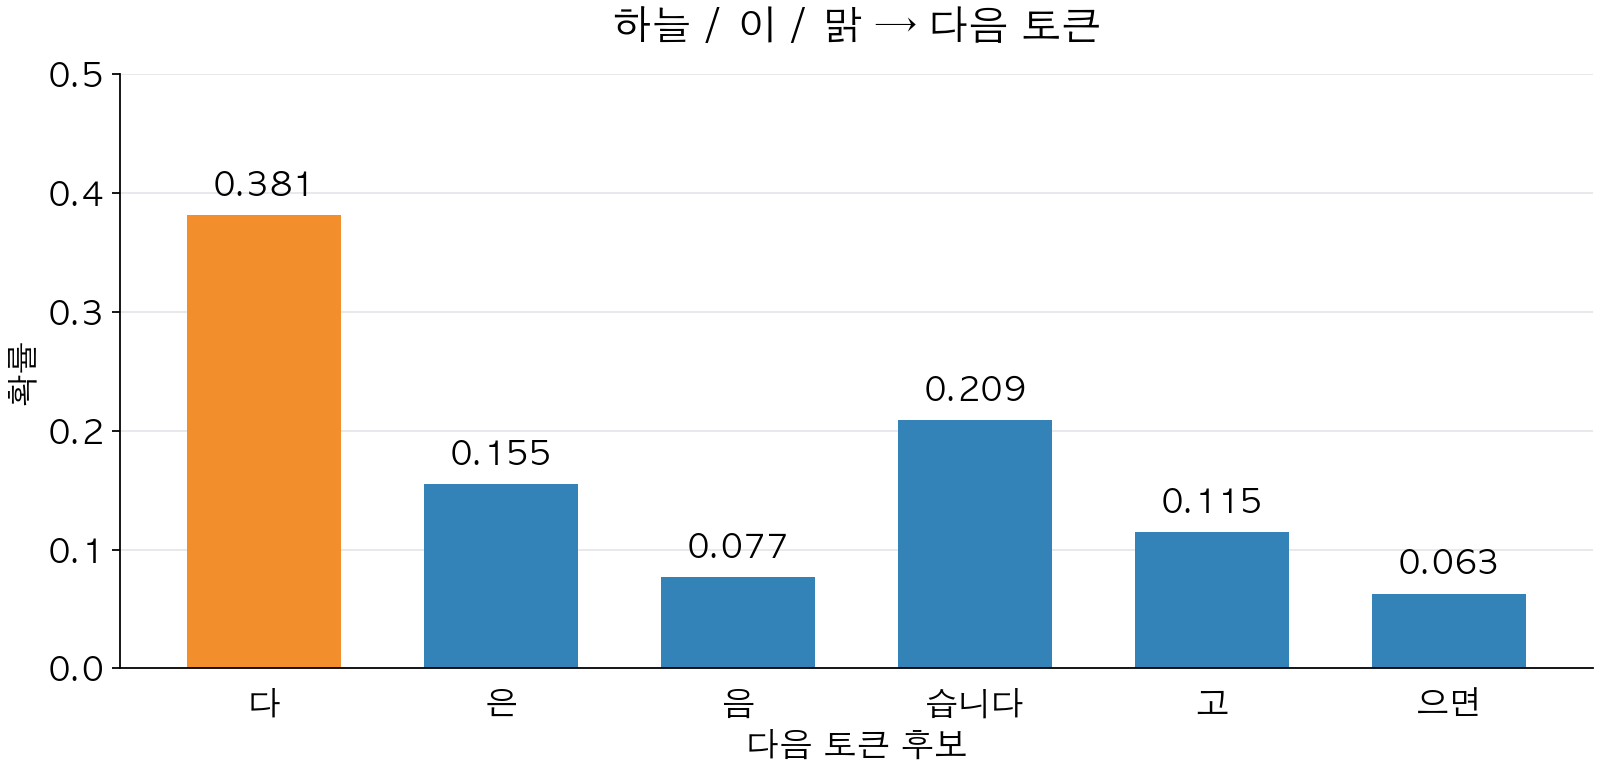

각 후보를 입력 뒤에 붙이면 다음과 같은 표현이 된다.

| 다음 토큰 | 이어 붙인 표현 |
| --- | --- |
| `다` | 하늘이 맑다 |
| `은` | 하늘이 맑은 … |
| `음` | 하늘이 맑음 |
| `습니다` | 하늘이 맑습니다 |
| `고` | 하늘이 맑고 … |
| `으면` | 하늘이 맑으면 … |


## Decoder-only 언어 모델

GPT, Llama, Qwen과 같은 Decoder-only 언어 모델은 Causal self-attention, FFN, 정규화와 잔차 연결로 구성된 블록을 여러 개 쌓은 구조다. 별도의 Encoder와 Encoder 출력을 참고하는 Cross-attention은 사용하지 않는다.

입력 문맥과 생성 중인 출력은 하나의 토큰열로 연결되어 같은 블록들을 통과한다. 각 위치는 자기 위치와 앞선 토큰을 참고하므로, 다음 토큰을 예측하는 데 입력 문맥과 이미 생성한 내용을 함께 활용할 수 있다.


## 자기회귀 생성

자기회귀(autoregressive) 생성은 선택한 토큰을 입력 뒤에 붙이고, 길어진 문맥으로 다음 토큰을 예측하는 과정을 반복하는 방식이다. 이때 모델의 가중치는 고정되어 있고 입력 토큰열이 길어진다. 다음 단계의 입력을 완성하려면 현재 단계의 토큰을 먼저 선택해야 하므로, 일반적인 자기회귀 생성은 토큰을 순차적으로 생성한다.


### 다음 토큰 선택하기

탐욕적 선택(greedy decoding)은 각 단계에서 가장 높은 확률의 토큰을 고르는 방법이다. 확률 분포에 따라 무작위로 뽑는 샘플링을 사용하면 같은 입력에서도 다른 결과가 나올 수 있다. 샘플링의 다양성은 temperature로 조절할 수 있다.

`<EOS>`(End of Sequence)는 시퀀스의 끝을 나타내는 특수 토큰이다. 이 토큰을 선택하거나 정해 둔 최대 생성 개수에 도달하면 생성을 멈춘다.


### 실제 생성 과정

토큰을 하나씩 생성하는 동안 앞선 토큰들은 그대로 유지된다. 반복 계산을 줄이기 위해 각 Transformer 층에서 계산한 Key·Value를 저장해 재사용하며, 이 저장 공간을 KV Cache라고 한다.

처음 입력 토큰열을 Causal mask를 적용해 함께 처리하고 KV Cache를 채우는 단계를 Prefill이라고 한다. 마지막 입력 위치의 출력으로 첫 생성 토큰을 선택한다.

이후에는 직전에 선택한 토큰 하나를 처리해 다음 토큰을 예측한다. 이 단계를 Decode라고 하며, 각 층에서 과거 K·V를 재사용하고 새 토큰의 K·V를 캐시에 추가한다.

입력이 `하늘 / 이 / 맑`이고 `다`, `<EOS>`이 차례로 선택되었다고 가정하면 다음과 같이 진행된다.

| 단계 | 새로 처리하는 토큰 | 재사용하는 K·V의 토큰 | 선택한 다음 토큰 |
| --- | --- | --- | --- |
| Prefill | 하늘 / 이 / 맑 | 없음 | `다` |
| Decode | 다 | 하늘 / 이 / 맑 | `<EOS>` |

